### 1. Load the Dataset & Exploratory Data Analysis (EDA)
We will start by importing the necessary libraries, loading the CSV file, and analyzing its structure, columns, and basic statistics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load the dataset
file_path = '/content/starbucks-menu-nutrition-drinks.csv'
df = pd.read_csv(file_path)

# Rename the unnamed index column if present
if df.columns[0].startswith('Unnamed'):
    df.rename(columns={df.columns[0]: 'Drink_Name'}, inplace=True)

# Display basic information and first few rows
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (177, 7)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Drink_Name  177 non-null    object
 1   Calories    177 non-null    object
 2   Fat (g)     177 non-null    object
 3   Carb. (g)   177 non-null    object
 4   Fiber (g)   177 non-null    object
 5   Protein     177 non-null    object
 6   Sodium      177 non-null    object
dtypes: object(7)
memory usage: 9.8+ KB

First 5 Rows:


,Drink_Name,Calories,Fat (g),Carb. (g),Fiber (g),Protein,Sodium
0,Cool Lime Starbucks Refreshers™ Beverage,45,0,11,0,0,10
1,Ombré Pink Drink,-,-,-,-,-,-
2,Pink Drink,-,-,-,-,-,-
3,Strawberry Acai Starbucks Refreshers™ Beverage,80,0,18,1,0,10
4,Very Berry Hibiscus Starbucks Refreshers™ Beve...,60,0,14,1,0,10



Missing Values:
Drink_Name    0
Calories      0
Fat (g)       0
Carb. (g)     0
Fiber (g)     0
Protein       0
Sodium        0
dtype: int64


### 2. Visualize Drink Categories with a Pie Chart
Let's clean any missing or dash ('-') placeholder values, classify the drinks based on calorie levels, and plot their distribution using a pie chart.

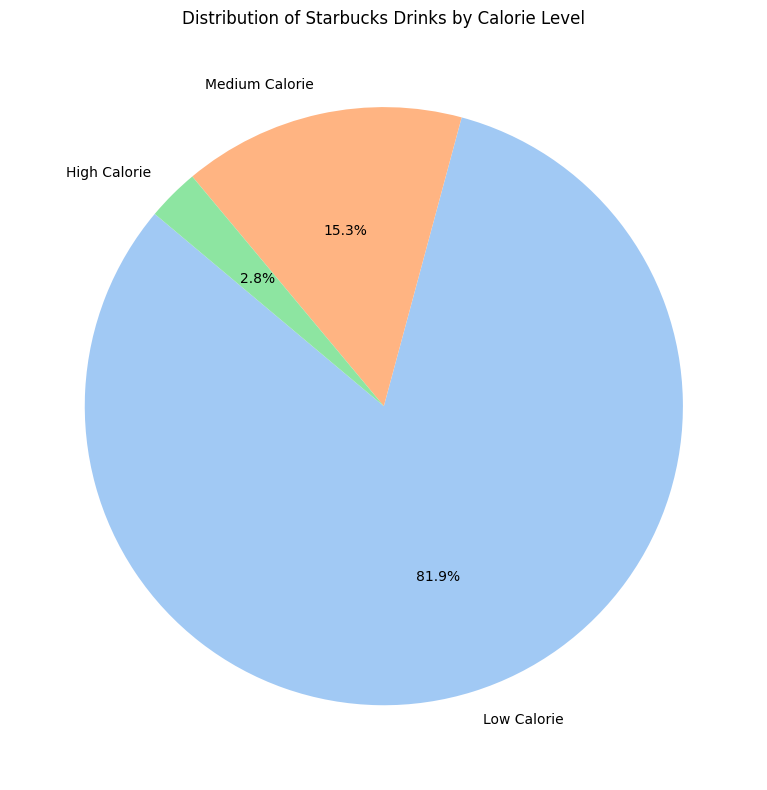

In [2]:
# Clean columns: replace '-' with NaN and convert numeric columns to float
numeric_cols = ['Calories', 'Fat (g)', 'Carb. (g)', 'Fiber (g)', 'Protein', 'Sodium']
for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.replace('-', 'nan').astype(float)

# Fill missing numeric values with their median
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Create a categorical target for classification: Calorie level
# Let's categorize drinks into 'Low Calorie' (<150), 'Medium Calorie' (150-300), and 'High Calorie' (>300)
def categorize_calories(cal):
    if cal < 150:
        return 'Low Calorie'
    elif cal <= 300:
        return 'Medium Calorie'
    else:
        return 'High Calorie'

df['Calorie_Category'] = df['Calories'].apply(categorize_calories)

# Plot a pie chart of the Calorie Categories
category_counts = df['Calorie_Category'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(category_counts, labels=category_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Distribution of Starbucks Drinks by Calorie Level')
plt.tight_layout()
plt.show()

### 3. Split the Data and Train a Decision Tree Classifier
We will define our features, split the data into training and validation sets, and train a Decision Tree model to predict the calorie level categories based on nutritional values.

In [3]:
# Define feature columns (using other nutritional values)
features = ['Fat (g)', 'Carb. (g)', 'Fiber (g)', 'Protein', 'Sodium']
X = df[features]
y = df['Calorie_Category']

# Split dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train Decision Tree model
clf = DecisionTreeClassifier(random_state=42, max_depth=5)
clf.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


### 4. Evaluate Model Performance
Now, let's make predictions on the test set and evaluate the model using accuracy and a classification report.

In [4]:
# Make predictions
y_pred = clf.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}")

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.9722

Classification Report:
                precision    recall  f1-score   support

  High Calorie       0.00      0.00      0.00         1
   Low Calorie       1.00      1.00      1.00        30
Medium Calorie       0.83      1.00      0.91         5

      accuracy                           0.97        36
     macro avg       0.61      0.67      0.64        36
  weighted avg       0.95      0.97      0.96        36



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### 5. Compare Actual vs. Predicted Labels for 10 Test Samples
We will take 10 drinks from the validation dataset, retrieve their drink names, actual calorie classes, and display them alongside our Decision Tree model predictions.

In [5]:
# Retrieve drink names matching the test indices
test_indices = X_test.head(10).index
test_drinks = df.loc[test_indices, 'Drink_Name'].values

# Get 10 actual and predicted samples
actual_samples = y_test.head(10).values
predicted_samples = y_pred[:10]

# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Drink Name': test_drinks,
    'Actual Category': actual_samples,
    'Predicted Category': predicted_samples
})

display(comparison_df)

,Drink Name,Actual Category,Predicted Category
0,Starbucks® Bottled S'mores Frappuccino® Coffee...,Low Calorie,Low Calorie
1,Cappuccino,Low Calorie,Low Calorie
2,Starbucks Doubleshot® Espresso Drink,Low Calorie,Low Calorie
3,Cupcake Crème Frappuccino® Blended Crème,Low Calorie,Low Calorie
4,Iced Espresso Classics - Caffe Mocha,Low Calorie,Low Calorie
5,Clover® Brewed Coffee,Low Calorie,Low Calorie
6,Starbucks Doubleshot® Energy Coffee Drink,Low Calorie,Low Calorie
7,Toasted Coconut Cold Brew,Low Calorie,Low Calorie
8,Caffè Misto,Low Calorie,Low Calorie
9,Iced Caffè Mocha,Medium Calorie,Medium Calorie
